# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel. 

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


--- 
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [1]:
# importar librerías
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
# cargar archivos
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv')
usage = pd.read_csv('/datasets/usage.csv')

In [3]:
plans.head(5)

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [4]:
users.head(5) #vemos que en la columna city existe un valor '?', esto podria ser un dato faltante 

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [5]:
usage.head(5) #encontramos que las columnas tienen duration y length tienen varios NaN porque la llamada 'call' tiene duracion pero no longitud de mensaje y un texto 'text' tiene longiutd pero no duracion

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [6]:

# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [7]:
# inspección de plans con .info()
plans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [8]:
# inspección de users con .info()
users.info()
# el dtype de reg_date y churn_date deberian ser datetime

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [9]:
# inspección de usage con .info()
usage.info()
# el dtype de DATE deberia ser datetime

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [10]:
# cantidad de nulos para users
print(users.isna().sum())
print(users.isna().sum()/users.shape[0])

user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64
user_id       0.00000
first_name    0.00000
last_name     0.00000
age           0.00000
city          0.11725
reg_date      0.00000
plan          0.00000
churn_date    0.88350
dtype: float64


In [11]:
# cantidad de nulos para usage
print(usage.isna().sum())
print(usage.isna().sum()/usage.shape[0])

id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64
id          0.00000
user_id     0.00000
type        0.00000
date        0.00125
duration    0.55190
length      0.44740
dtype: float64


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico al final del bloque. Incluye qué ves y que acción recomendarías para cada caso.

💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).
* Hint:
 - Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.  
 - Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.  
 - Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos. 
 
 ---

**Valores nulos**  
- ¿Qué columnas tienen valores faltantes y en qué proporción?
   RTA: DE USERS encontramos que de la columna CITY tiene el 11%de datos faltantes y CHURN DATE hacen falta el 88% de los datos.
   DE USAGE vemos que de la columna DATE hacen falta el 0.12% de los datos, DURATION tiene un faltante del 55% y de LENGTH hacen falta el 44% de los datos. 
- Indica qué harías: ¿imputar, eliminar, ignorar?
  RTA: DE USERS encontramos que de la columna CITY tiene el 11% faltante en datos, deberiamos dejarlo como nulos ya que si usaramos la moda para encontrar el valor mas frecuente no estaria bien asumir que un cliente sin ciudad registrada viva en la ciudad mas comun y de CHURN DATE hacen falta el 88% de los datos  la mejor opcion seria ignorar aunque eso nos dejaria una pregunta si es la fecha de la cancelacion de su servicio pero si el cliente no ha cancelado ¿sigue activo?

### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [12]:
# explorar columnas numéricas de users

- La columna `user_id` ... Haz doble clic en este bloque y escribe qué ves.
- La columna `age` ...

In [13]:
# explorar columnas numéricas de usage

- Las columnas `id` y `user_id`...Haz doble clic en este bloque y escribe qué ves.
- Las columnas ...

In [14]:
# explorar columnas categóricas de users
columnas_user = ['city', 'plan']


- La columna `city` ...
- La columna `plan` ...

In [15]:
# explorar columna categórica de usage
usage['type'] # completa el código

0        call
1        text
2        text
3        call
4        call
         ... 
39995    call
39996    call
39997    call
39998    text
39999    call
Name: type, Length: 40000, dtype: object

- La columna `type` ...


---
✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías para cada caso. 

**Valores inválidos o sentinels**  
- ¿En qué columnas encontraste valores inválidos o sentinels?  
- ¿Qué acción tomarías?  

### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [16]:
# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = # completa el código

SyntaxError: invalid syntax (2049554652.py, line 2)

In [ ]:
# Convertir a fecha la columna `date` de usage
usage['date'] = # completa el código

In [ ]:
# Revisar los años presentes en `reg_date` de users


En `reg_date`, ... haz doble clic en este bloque y escribe qué ves.

In [ ]:
# Revisar los años presentes en `date` de usage


En `date`, ... haz doble clic en este bloque y escribe qué ves.  
Basaremos el análisis en estas fechas.

✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:

**Fechas fuera de rango**  
- ¿Aparecen años imposibles? (años muy viejos o sin transcurrir al momento de guardar los datos)
- ¿Qué harías con ellas?

---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [17]:
# Reemplazar -999 por la mediana de age
age_mediana = users[users['age']!=-999]['age'].median()
users.loc[users['age']==-999, 'age'] = age_mediana

# Verificar cambios
users['age'].describe()

count    4000.000000
mean       48.136000
std        17.689919
min        18.000000
25%        33.000000
50%        48.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [18]:
users['reg_date'] = pd.to_datetime (users['reg_date'], errors = 'coerce')

In [19]:
# Marcar fechas futuras como NA para reg_date
users.loc[users['reg_date'] > pd.Timestamp.today(), 'reg_date'] = pd.NaT

# Verificar cambios

In [20]:
# Reemplazar ? por NA en city
users.loc[users['city']== '?', 'city'] = pd.NA
# Verificar cambios

### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [21]:
# Verificación MAR en usage (Missing At Random) para duration
usage.groupby('type')['duration'].apply (lambda x: x.isna().sum())

type
call        0
text    22076
Name: duration, dtype: int64

In [22]:
# Verificación MAR en usage (Missing At Random) para length
usage.groupby('type')['length'].apply (lambda x: x.isna().sum())

type
call    17896
text        0
Name: length, dtype: int64

Haz doble clic aquíy escribe que tu diagnostico de nulos en `duration` y `length`
RTA: los valores nulos de DURATION corresponden a text porque una llamada no tiene texto y los valores nulos de LENGTH corresponden a call ya que un mensaje no tiene largo de llamada por esta razon se justificaria dejarlos 

---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico. 

**Instrucciones:**: 
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [23]:
# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int) #conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int) #conocer el total de llamadas


# Agrupar información por usuario

usage_agg = usage.groupby('user_id').agg(cant_minutos_llamadas=('duration', 'sum'), cant_mensajes=('is_text', 'sum'), cant_llamadas= ('is_call', 'sum')).reset_index()


# observar resultado
usage_agg.head(3)

,user_id,cant_minutos_llamadas,cant_mensajes,cant_llamadas
0,10000,23.70,7,3
1,10001,33.18,5,10
2,10002,10.74,5,2


In [24]:
# Renombrar columnas
# se remonbraron en el agg anterior
# observar resultado
usage_agg.head(3)

,user_id,cant_minutos_llamadas,cant_mensajes,cant_llamadas
0,10000,23.70,7,3
1,10001,33.18,5,10
2,10002,10.74,5,2


In [25]:

# Combinar la tabla agregada con el dataset de usuarios
user_profile = users.merge(usage_agg, on= 'user_id', how='inner')
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_minutos_llamadas,cant_mensajes,cant_llamadas
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,23.70,7,3
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,33.18,5,10
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,10.74,5,2
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,8.99,11,3
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,8.01,4,3


### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [26]:
# Resumen estadístico de las columnas numéricas
user_profile.describe()

,user_id,age,cant_minutos_llamadas,cant_mensajes,cant_llamadas
count,3999.000000,3999.000000,3999.000000,3999.000000,3999.000000
mean,11999.729432,48.138285,23.317054,5.524381,4.478120
std,1154.898108,17.691541,18.168095,2.358416,2.144238
min,10000.000000,18.000000,0.000000,0.000000,0.000000
25%,10999.500000,33.000000,11.120000,4.000000,3.000000
50%,12000.000000,48.000000,19.780000,5.000000,4.000000
75%,12999.500000,63.000000,31.415000,7.000000,6.000000
max,13999.000000,79.000000,155.690000,17.000000,15.000000


In [27]:
# Distribución porcentual del tipo de plan
user_profile['plan'].value_counts(normalize=True)
# el 65% de los planes pertenece al espectro Basico y el restante 35% pertenece al plan Premium

Basico     0.648662
Premium    0.351338
Name: plan, dtype: float64

---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada` 

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda) 

**Hint**  
Para cada histograma, 
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

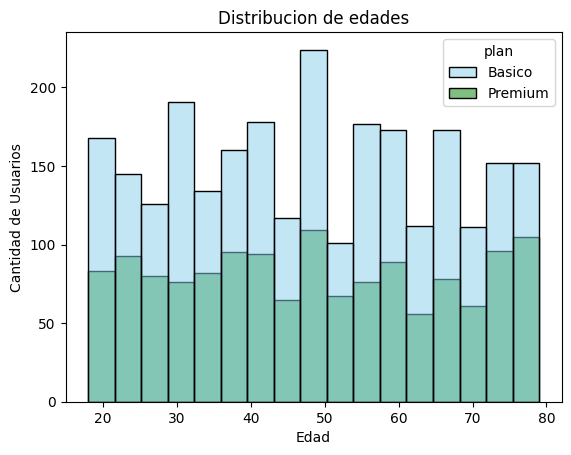

In [28]:
# Histograma para visualizar la edad (age)
sns.histplot(data = user_profile, x= 'age', hue= 'plan', palette=['skyblue','green'])
plt.title ('Distribucion de edades')
plt.xlabel ('Edad')
plt.ylabel ('Cantidad de Usuarios')
plt.show()

💡Insights: La grafica de edades de los usuarios es amplia y se extiende de forma relativamente uniforme desde los 18 hasta los 79 años, con un punto máximo de concentración cerca de los 50 años, se observa que el plan básico predomina de manera constante en casi todos los rangos de edad en comparación con el plan Premium, lo que indica que la elección del plan no está fuertemente sesgada por la edad del cliente.

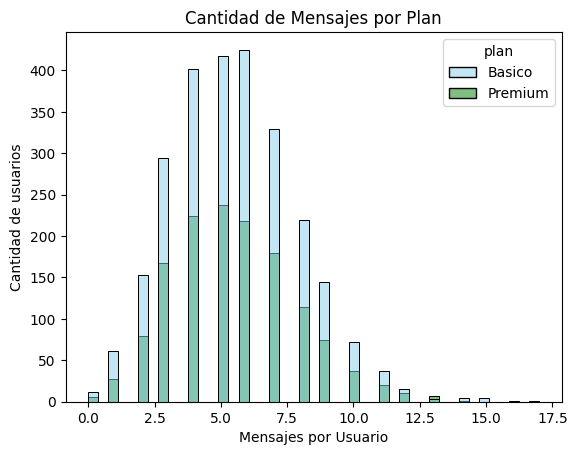

In [29]:
# Histograma para visualizar la cant_mensajes
sns.histplot (data = user_profile, x= 'cant_mensajes', hue= 'plan', palette=['skyblue', 'green'])
plt.title ('Cantidad de Mensajes por Plan')
plt.xlabel('Mensajes por Usuario')
plt.ylabel('Cantidad de usuarios')
plt.show()

💡Insights: La distribución de la cantidad de mensajes por usuario presenta un sesgo a la derecha, con la gran mayoría de los clientes concentrando su consumo entre 4 y 6 mensajes. Al desglosarlo por tipo de plan, se observa que la proporción entre usuarios del plan básico se mantiene bastante equilibrada en los niveles de consumo habituales. No obstante, los usuarios que alcanzan los valores más altos o extremos de mensajería pertenecen en su mayoría al plan básico.

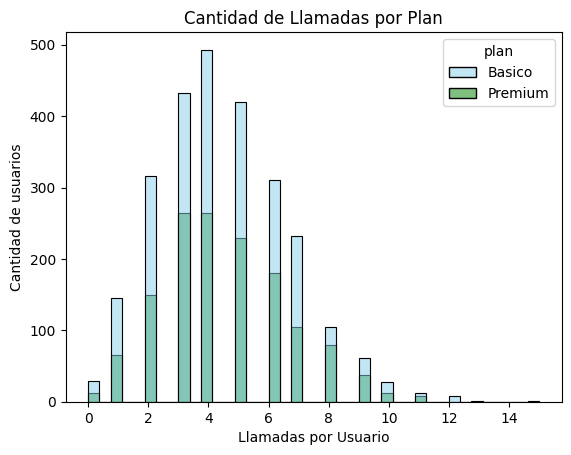

In [30]:
# Histograma para visualizar la cant_llamadas
sns.histplot (data = user_profile, x= 'cant_llamadas', hue= 'plan', palette=['skyblue', 'green'])
plt.title ('Cantidad de Llamadas por Plan')
plt.xlabel('Llamadas por Usuario')
plt.ylabel('Cantidad de usuarios')
plt.show()

💡Insights: El grafico de cantidad de llamadas por usuario muestra un sesgo a la derecha, indicando que la gran mayoría de los clientes realizan un volumen moderado de llamadas, concentrándose principalmente entre 3 y 5 llamadas por ususario. Al segmentar por tipo de plan, se observa que la proporción entre los usuarios del plan básico y Premium se mantiene bastante equilibrada en los niveles de consumo habituales y bajos.

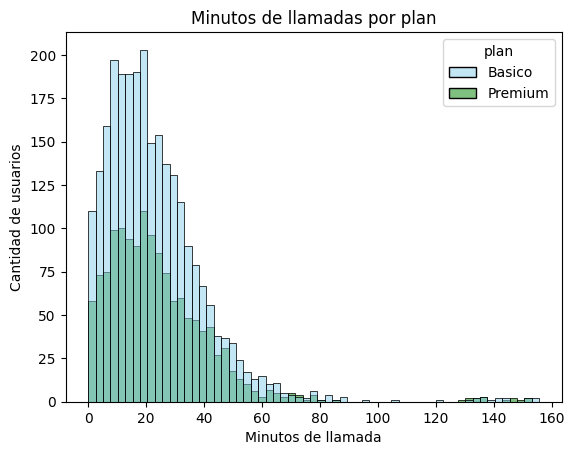

In [31]:
# Histograma para visualizar la cant_minutos_llamada
sns.histplot(data = user_profile, x= 'cant_minutos_llamadas', hue= 'plan', palette= ['skyblue', 'green'])
plt.title ('Minutos de llamadas por plan')
plt.xlabel ('Minutos de llamada')
plt.ylabel ('Cantidad de usuarios')
plt.show()

💡Insights: La distribución presenta un sesgo a la derecha, donde la gran mayoría de los clientes concentran su consumo en un rango bajo-moderado, principalmente entre los 10 y 25 minutos en el periodo analizado. Al segmentar por tipo de plan, se observa que la proporción entre los usuarios del plan básico y premium se mantiene muy constante en los niveles habituales de consumo. No obstante, es llamativa la presencia de una pequeña cola de valores atípicos, vemos un outlier que se extiende hacia la derecha superando los 120 e incluso alcanzando los 150 minutos.

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age` 
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

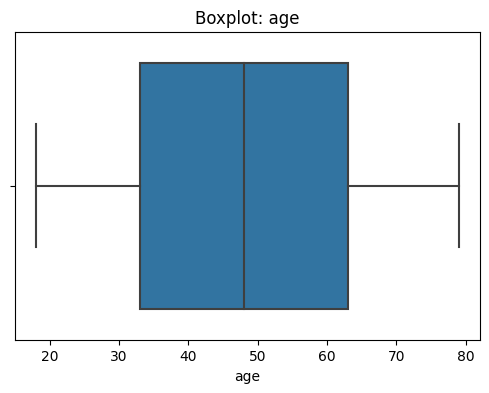

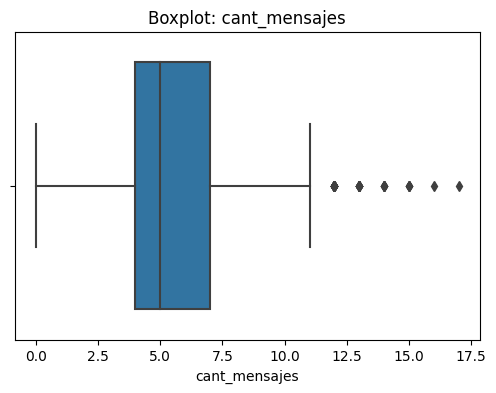

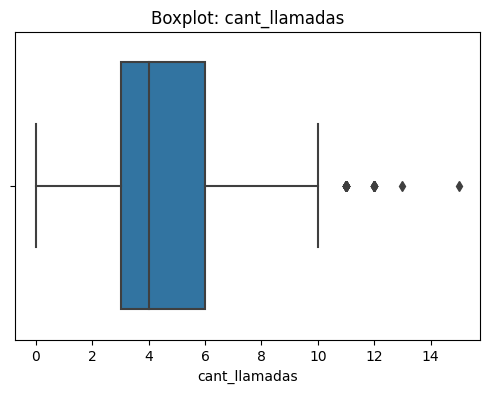

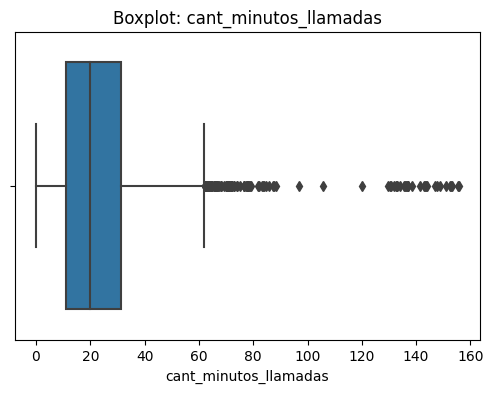

In [32]:
# Visualizando usando BoxPlot 
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamadas']


for col in columnas_numericas: 
    plt.figure(figsize=(6,4))
    sns.boxplot(x=user_profile[col])
    plt.title(f'Boxplot: {col}')
    plt.xlabel(col)
    plt.show()

💡Insights: 
- Age: no presenta ningun outlier porque los bigotes estan dentro de los minimos y maximos
- cant_mensajes: si se presentan outliers ya que algunos usuarios envian mensajes con un volumen mayor al de la gran mayoria
- cant_llamadas: si existen outliers en los valores 11,12,13 y 15 y se podrian considerar como un comportamiento mayor al habitual
- cant_minutos_llamada: si existen outliers y es un comportamiento que esta por fuera de la gran mayoria de los usuarios

In [33]:
# Calcular límites con el método IQR
columnas_limites = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamadas']


for col in columnas_numericas:
   Q1 = user_profile[col].quantile(0.25)
   Q3 = user_profile[col].quantile(0.75)
   IQR = Q3 - Q1
   limite_inferior = Q1 - 1.5*IQR
   limite_superior = Q3 + 1.5*IQR
   outliers = user_profile[(user_profile[col] < limite_inferior) | (user_profile[col] > limite_superior)]
   print(col, len(outliers))

age 0
cant_mensajes 46
cant_llamadas 30
cant_minutos_llamadas 109


In [34]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()

,age,cant_mensajes,cant_llamadas,cant_minutos_llamadas
count,3999.000000,3999.000000,3999.000000,3999.000000
mean,48.138285,5.524381,4.478120,23.317054
std,17.691541,2.358416,2.144238,18.168095
min,18.000000,0.000000,0.000000,0.000000
25%,33.000000,4.000000,3.000000,11.120000
50%,48.000000,5.000000,4.000000,19.780000
75%,63.000000,7.000000,6.000000,31.415000
max,79.000000,17.000000,15.000000,155.690000


💡Insights: 
- cant_mensajes: mantener o no outliers, porqué? Mantener, puesto que enviar entre 12 y 17 mensajes en todo el periodo analizado es un comportamiento totalmente real (incluso está muy por debajo de los 100 mensajes que incluye el plan básico). No son errores de registro, sino usuarios que simplemente textean un poco más que el promedio. 
- cant_llamadas: mantener o no outliers, porqué? Mantener, porque realizar de 11 a 15 llamadas es un volumen completamente normal y orgánico para un cliente con un plan de telefono celular. Eliminarlos borraría a clientes reales con un uso ligeramente superior a la media.
- cant_minutos_llamada: mantener o no outliers, porqué? Mantener, ya que Aunque la distancia entre el límite superior (62) y el máximo (156), sigue siendo un consumo realista (equivale a poco más de 2 horas y media de llamadas en total). Para el negocio, estos usuarios son muy valiosos: si están en el plan básico (que solo incluye 100 minutos), representan clientes que generan ingresos extra por excedentes o son candidatos ideales para migrar al plan premium.

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [35]:
# Crear columna grupo_uso
def clasificar_uso (row):
    if row['cant_llamadas'] < 5 and row ['cant_mensajes'] < 5:
        return 'Bajo uso'
    elif row ['cant_llamadas'] < 10 and row ['cant_mensajes'] < 10:
        return 'Uso medio'
    else: 
        return 'Alto uso'

In [39]:
user_profile['grupo_uso'] = user_profile.apply(clasificar_uso, axis=1)

In [40]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_minutos_llamadas,cant_mensajes,cant_llamadas,grupo_uso
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,23.70,7,3,Uso medio
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,33.18,5,10,Alto uso
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,10.74,5,2,Uso medio
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,8.99,11,3,Alto uso
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,8.01,4,3,Bajo uso


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [44]:
# Crear columna grupo_edad
def clasificar_edad (row):
    if row ['age'] < 30:
        return 'Joven'
    elif row ['age'] < 60:
        return 'Adulto'
    else:
        return 'Adulto mayor'


In [45]:
user_profile['grupo_edad'] = user_profile.apply(clasificar_edad, axis=1)

In [46]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_minutos_llamadas,cant_mensajes,cant_llamadas,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,23.70,7,3,Uso medio,Adulto
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,33.18,5,10,Alto uso,Adulto
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,10.74,5,2,Uso medio,Adulto
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,8.99,11,3,Alto uso,Adulto mayor
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,8.01,4,3,Bajo uso,Adulto mayor


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

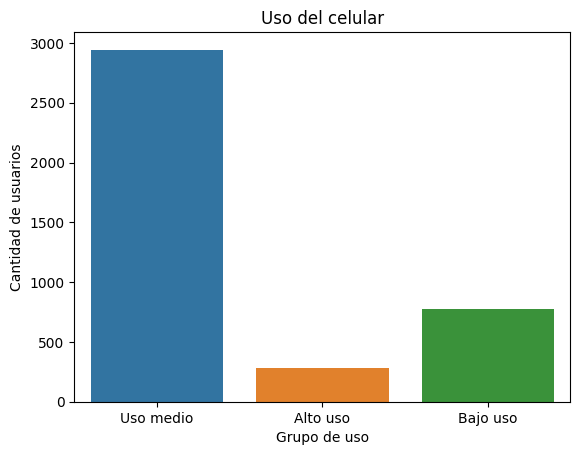

In [48]:
# Visualización de los segmentos por uso
sns.countplot(data = user_profile, x = 'grupo_uso')
plt.title ('Uso del celular')
plt.xlabel ('Grupo de uso')
plt.ylabel ('Cantidad de usuarios')
plt.show()

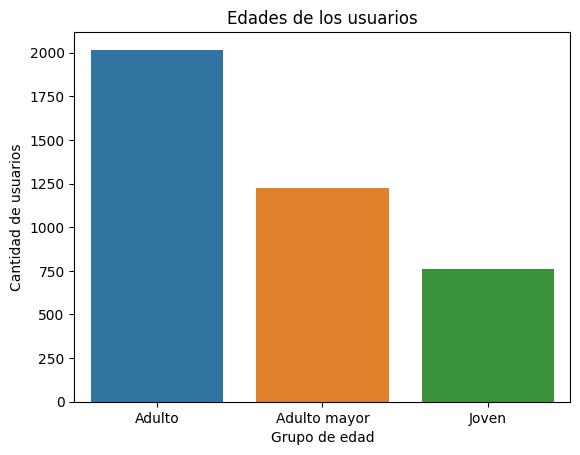

In [50]:
# Visualización de los segmentos por edad
sns.countplot(data = user_profile, x = 'grupo_edad')
plt.title ('Edades de los usuarios')
plt.xlabel ('Grupo de edad')
plt.ylabel ('Cantidad de usuarios')
plt.show()


---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:** 
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?
   En la columna churn_date se encontraron el 88% de valores nulos que podrian indicar la tasa de cancelacion pero esto no fue asi ya que los usuarios seguian activos y por ende se decidio dejar eso valores nulos.
   De los 4000 usuarios el 11% es decir 469 usuarios tenian como registro (?), se determina dejarlos como evitar sesgos. 

- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?
  Hablando del uso por edades se podria determinar que el bajo uso podria ser que los jovenes usan las gibas unicamente y dejan a un lado los mensajes y los minutos y el alto uso podria pertencer a los adultos entre los 30 y los 59 años quienes representan el 50% de los usuarios y serian los que mas usan los minutos y los adultos mayores conforman un porcentaje importante ya que estos tienden a concentrar su actividad principalmente a las llamadas de voz tradicionales.
   
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?
   Los usuarios de Alto Uso y los outliers en minutos que actualmente tienen  el plan básico (cuyo límite es de 100 minutos), ya que generan ingresos adicionales por consumo excedente ($0.10 USD/min) y tienen alta propensión a requerir una actualización de plan.
 
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?
  Se identificaron outliers superiores: 46 usuarios en mensajes (máx. 17), 30 usuarios en llamadas (máx. 15) y 109 usuarios en minutos de llamada (superando el límite IQR de ~61.86 min hasta un máximo de 155.69 min).

- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?
   Se propone crear dos planes adicionales con el objetivo de ampliar las posibilidades para los clientes variando la oferta de minutos, mensajes y gbs por plan. El nuevo Plan Estandar cuesta $16/mes e incluye 200 mensajes, 10 gbs y 200 minutos, costos($1.15/gb, $0.07/mensaje, $0.09/minuto)
El nuevo Plan Pro cuesta $20/mes e incluye 300 mensajes, 15 gbs y 300 minutos, costos ($1.05/gb, $0.06/mensaje, $0.08/minuto). 

✍️ **Escribe aquí tu análisis ejecutivo:**

### Análisis ejecutivo

⚠️ **Problemas detectados en los datos**
- La columna city en users presenta un 11% de datos faltantes, registrados originalmente como valor sentinel (?), se dejaron esos valores nulos en ves de imputarlos con la moda ya que asumir la ciudad mas comun a estos usuarios seria sesgar la ubicacion real de estos mismos.
- En las columnas duration y length se encontraron valores nulos del 55% y 44%, estos valores corresponden a MAR, ya que una llamada tiene duracion mas no longitud (length), y un mensaje de texto tiene longitud mas no duracion, por esta razon se justifica dejarlos como nulos. 


🔍 **Segmentos por Edad**
- La edad de la poblacion de ConnectaTel se encuentra entre los 18 y los 79 años en donde la mediana es de 48 años, siendo el segmento Adulto como el nucleo princiapl del negocio llegando casi al 50%.
- Si se llegara a crear los dos nuevos planes se podrian pensar en mas gibas para los jovenes y mas minutos de voz para los segmentos de adulto y adulto mayor.


📊 **Segmentos por Nivel de Uso**
- Al tomar de referencia la grafica de grupo de uso se podria suponer que las personas que estan dentro del alto uso podrian llegar a pensar en abandonar la compañia porque al estar en esta parte de la grafica pueden podrian estar enfrentando cargos por extras en su cobro si no se ofrece un plan diferente entre el Basico y el Premium  como el Pro o reestructurar el plan Premium.
- Al interpretar la grafica vemos que no solo hay uso alto o bajo sino que tambien existe la parte media y que los 250 o 300 usuarios que se encuentran aca podrian estar dispuestos a cambiar su plan sin dar el salto tan grande como pasar al Plan Premium sino que podrian migrar al Estandar o al Pro.


💡 **Recomendaciones**
- Se recomienda crear dos planes adicionales que se encuentren entre los planes Basico y Premium, estos dos nuevos planes serian Estandar y Pro, al crear estos planes podriamos reducir la tasa de cancelacion considerando que hay una brecha muy amplia entre los valores a pagar entre el plan Basico ($12) y el Premium($25), el objetivo de tener mas opciones para los usuarios tambien radica en que los jovenes usan o pueden estar buscando mas gibas y los adultos estan necesitando mas minutos, con el fin que el usuario sienta que el plan se ajusta a su medida. La idea de tener 4 planes tambien tiene como objetivo impactaria sicologicamente en el usuario ya que al ofrecer el Plan Pro por $20 haria que el plan Premium seria una opcion atractiva por $5 adicionales aumentando los beneficios, incentivando que las personas suban de plan y lo mismo pasaria con el Plan Basico al Plan Estandar.

---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`